# Analyse exploratoire : prédiction du churn client (Telco)
Objectif : comprendre quels clients quittent l'entreprise et pourquoi, avant de construire un modèle prédictif.

In [1]:
import pandas as pd
df = pd.read_csv("../data/telco_churn.csv")
print(df.shape)
df.head()


(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [3]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print(df["TotalCharges"].isna().sum())

11


In [4]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## Nettoyage des données
La colonne `TotalCharges` était lue comme du texte. Je l'ai convertie en nombre.
11 valeurs vides correspondaient à des clients tout nouveaux (ancienneté = 0), remplacées par 0.
Aucun doublon détecté.

In [5]:
print(df.duplicated().sum())
print(df["customerID"].duplicated().sum())

0
0


In [6]:
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True))

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


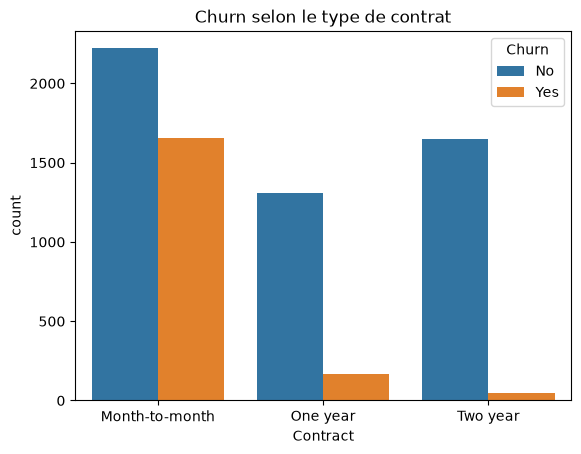

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Churn selon le type de contrat")
plt.show()

### Churn selon le type de contrat
Les clients en contrat mensuel partent beaucoup plus.Environ 1650 départs, contre environ 170 en contrat d'un an et moins de 50 en contrat de deux ans. L'engagement long protège fortement contre le churn.

In [8]:
df["Churn_num"] = (df["Churn"] == "Yes").astype(int)
print(df["Churn_num"].mean())

0.2653698707936959


## Taux de churn global
Environ 26,5 % des clients sont partis. Le jeu de données est déséquilibré (beaucoup plus de clients restés que partis). Il faudra donc en tenir compte pour la modélisation, et ne pas se fier à l'accuracy seule.

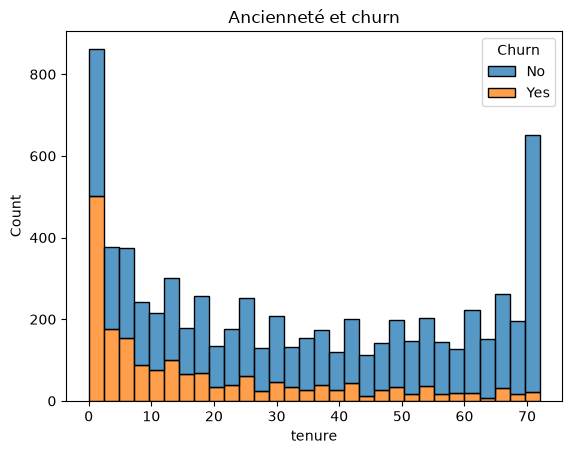

In [9]:
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, multiple="stack")
plt.title("Ancienneté et churn")
plt.show()

### Churn selon l'ancienneté
Le churn est concentré sur les tout premiers mois, près de 500 clients partent avant 3 mois d'ancienneté, puis les départs diminuent nettement. À l'inverse, les clients très anciens (autour de 70 mois) restent presque tous. La période d'intégration est donc critique.

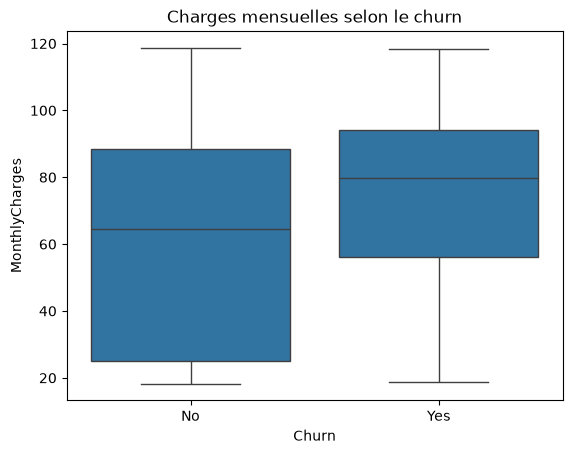

In [10]:
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Charges mensuelles selon le churn")
plt.show()

### Churn selon les charges mensuelles
Les clients qui partent paient en moyenne plus cher. La médiane est d'environ 80 € contre environ 65 € pour ceux qui restent. Le prix semble être un facteur de départ.

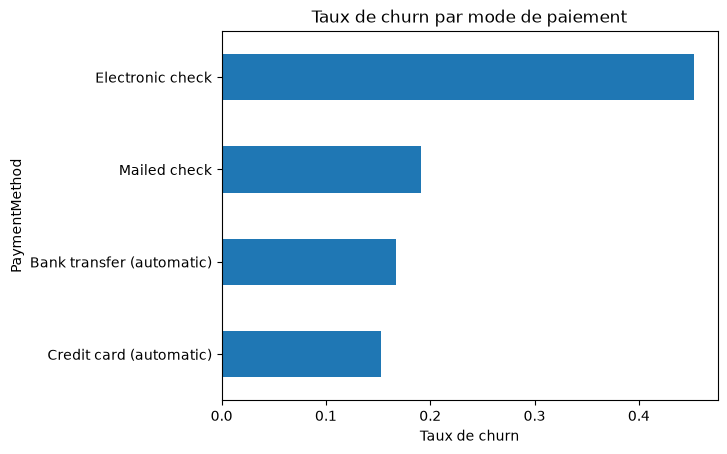

In [11]:
churn_paiement = df.groupby("PaymentMethod")["Churn_num"].mean().sort_values()
churn_paiement.plot(kind="barh")
plt.title("Taux de churn par mode de paiement")
plt.xlabel("Taux de churn")
plt.show()

### Churn selon le mode de paiement
Le paiement par Electronic check a un taux de churn d'environ 45 %, contre 15 à 19 % pour les autres modes. Les paiements automatiques (virement, carte) sont associés à moins de départs.

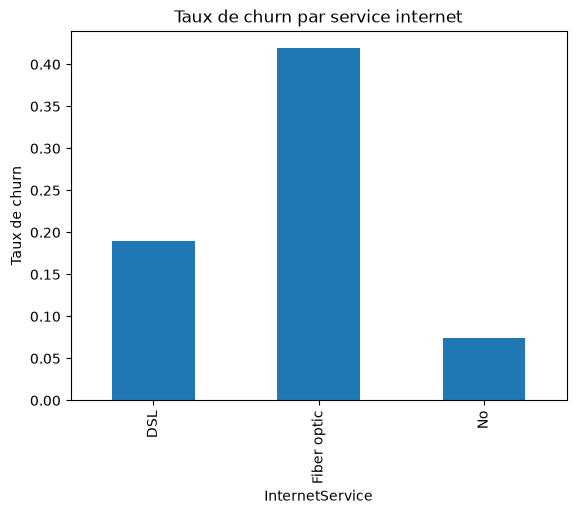

In [13]:
df.groupby("InternetService")["Churn_num"].mean().plot(kind="bar")
plt.title("Taux de churn par service internet")
plt.ylabel("Taux de churn")
plt.show()

### Churn selon le service internet
Les clients en fibre optique partent le plus (environ 42 %), contre environ 19 % pour le DSL et environ 7 % pour les clients sans internet. Cela peut venir du prix plus élevé ou de la qualité de service.

In [14]:
print(df.groupby("Contract")["Churn_num"].mean())

Contract
Month-to-month    0.427097
One year          0.112695
Two year          0.028319
Name: Churn_num, dtype: float64


## Conclusion de l'analyse exploratoire
Le profil type du client à risque est: 
 contrat mensuel, peu d'ancienneté, charges mensuelles élevées, paiement par electronic check, fibre optique.
Ces variables seront probablement importantes pour le modèle. 